In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import duckdb as dd
import os

In [31]:
db_path = "DB/"

customers = pd.read_csv(os.path.join(db_path,"olist_customers_dataset.csv"))
geolocations = pd.read_csv(os.path.join(db_path,"olist_geolocation_dataset.csv"))
order_items = pd.read_csv(os.path.join(db_path,"olist_order_items_dataset.csv"))
order_payments = pd.read_csv(os.path.join(db_path,"olist_order_payments_dataset.csv"))
order_reviews = pd.read_csv(os.path.join(db_path,"olist_order_reviews_dataset.csv"))
orders = pd.read_csv(os.path.join(db_path,"olist_orders_dataset.csv"))
products = pd.read_csv(os.path.join(db_path,"olist_products_dataset.csv"))
sellers = pd.read_csv(os.path.join(db_path,"olist_sellers_dataset.csv"))

complete table for power BI

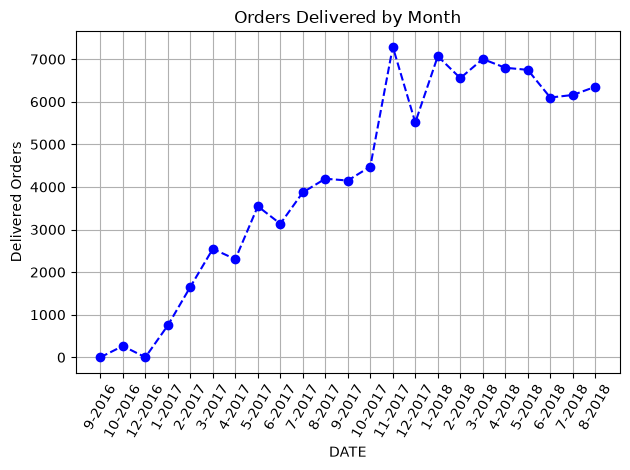

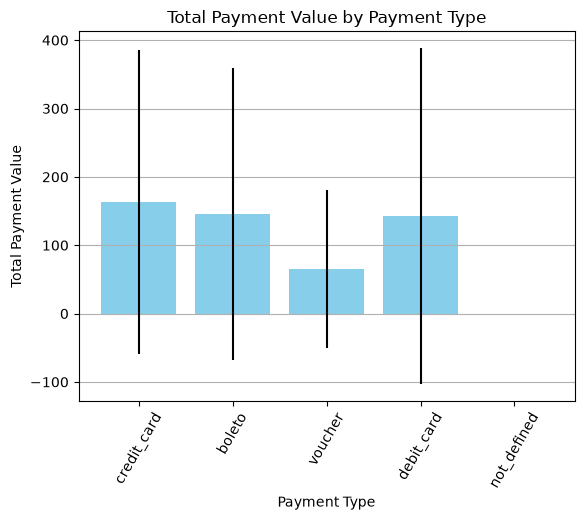

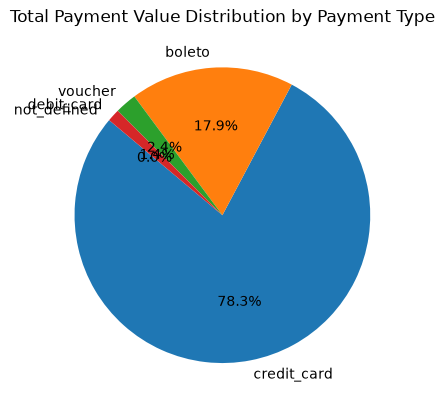

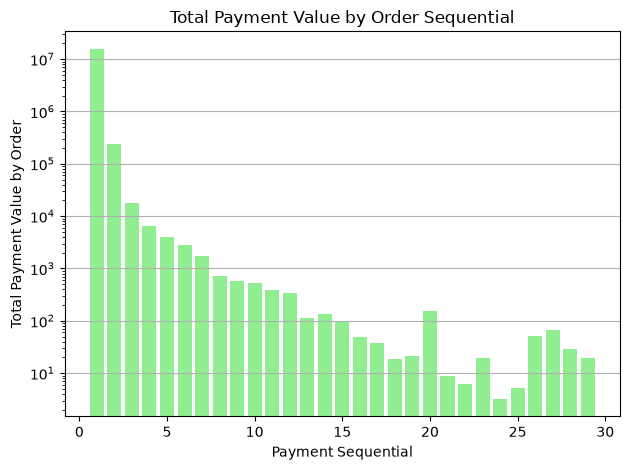

In [50]:
orders_by_month = dd.query(
    """
    SELECT
        EXTRACT(YEAR FROM CAST(order_purchase_timestamp AS TIMESTAMP)) AS year,
        EXTRACT(MONTH FROM CAST(order_purchase_timestamp AS TIMESTAMP)) AS month,
        COUNT(*) AS delivered_by_month
    FROM orders
    WHERE order_status = 'delivered'
    GROUP BY year, month
    ORDER BY year, month
    """
)

orders_by_month_df = orders_by_month.to_df()
orders_by_month_df['month_year'] = orders_by_month_df['month'].astype(str) + '-' + orders_by_month_df['year'].astype(str)

plt.plot(orders_by_month_df['month_year'], orders_by_month_df['delivered_by_month'], marker='o', linestyle='--', color='b')
plt.xlabel('DATE')
plt.ylabel('Delivered Orders')
plt.title('Orders Delivered by Month')
plt.xticks(rotation=60)
plt.grid(True)
plt.tight_layout()
plt.show()



payments_behaviour = dd.query(
    """
    SELECT SUM(payment_value) AS total_payment_value, 
    AVG(payment_value) AS average_payment_value, 
    STDDEV(payment_value) AS standard_deviation, payment_type
    FROM order_payments
    GROUP BY payment_type
    ORDER BY total_payment_value DESC
    """
)

payments_behaviour_df = payments_behaviour.to_df()
#print(payments_behaviour_df)
plt.bar(payments_behaviour_df['payment_type'], payments_behaviour_df['average_payment_value'],
         yerr=payments_behaviour_df['standard_deviation'], color='skyblue')
plt.xlabel('Payment Type')
plt.ylabel('Total Payment Value')
plt.title('Total Payment Value by Payment Type')
plt.xticks(rotation=60)
plt.grid(axis='y')
plt.show()

# Este grafico se puede mejorar esteticamente, separar los numeros para porcentajes tan pequeños.
plt.pie(payments_behaviour_df['total_payment_value'], labels=payments_behaviour_df['payment_type'], autopct='%1.1f%%', startangle=140)
plt.title('Total Payment Value Distribution by Payment Type')
plt.show()



payments_by_order = dd.query(
    """
    SELECT SUM(payment_value) AS total_payment_by_order, payment_sequential
    FROM order_payments
    GROUP BY payment_sequential
    ORDER BY total_payment_by_order DESC
    """
)

payments_by_order_df = payments_by_order.to_df()
#print(payments_by_order_df)
plt.bar(payments_by_order_df['payment_sequential'], payments_by_order_df['total_payment_by_order'], color='lightgreen')
plt.xlabel('Payment Sequential')
plt.ylabel('Total Payment Value by Order')
plt.title('Total Payment Value by Order Sequential')
plt.yscale('log')
plt.grid(axis='y')
plt.tight_layout()
plt.show()




In [32]:
result = dd.query("""
SELECT *
FROM orders
INNER JOIN order_payments
ON orders.order_id = order_payments.order_id
INNER JOIN order_reviews
ON orders.order_id = order_reviews.order_id
INNER JOIN order_items
ON orders.order_id = order_items.order_id
INNER JOIN products
ON order_items.product_id = products.product_id
INNER JOIN sellers
ON order_items.seller_id = sellers.seller_id
INNER JOIN customers
ON orders.customer_id = customers.customer_id
INNER JOIN geolocations
ON customers.customer_zip_code_prefix = geolocations.geolocation_zip_code_prefix

""")